# Филогенетический анализ семейства Ursidae

В этом проекте исследуем эволюционные отношения восьми современных видов медведей на основе двух генов: ядерного IRBP и митохондриального CYTB. В качестве внешней группы используем Panthera pardus.

Последовательности получаем из NCBI GenBank с помощью NCBI E-utilities через модуль Bio.Entrez библиотеки Biopython. Для выравнивания используем MAFFT, для фильтрации — TrimAl, а для объединения генов — SequenceMatrix.

Филогенетические деревья строим методами Neighbor-Joining и Maximum Likelihood (IQ-TREE). Также сравниваем результаты с разными схемами разделения данных.


### 1. Загружаем данные

In [1]:
from Bio import Entrez, SeqIO

Entrez.email = "h6233239@gmail.com"

**Поиск последовательностей гена IRBP**

In [2]:
query = '"Yu L"[AUTH] AND Ursidae[ORGN] AND irbp[TITL]'

handle = Entrez.esearch(db="nucleotide", term=query, retmax=100)
record = Entrez.read(handle)
handle.close()

print("Number of results:", record["Count"])
print("Sequence IDs:", record["IdList"])

Number of results: 8
Sequence IDs: ['34732767', '34732765', '34732763', '34732761', '34732759', '34732757', '34732755', '34732753']


### Загрузка последовательностей IRBP

С помощью `Entrez.efetch()` скачиваем найденные последовательности и сохраняем их в файл `irbp.fasta`.

In [ ]:
handle = Entrez.efetch(
    db="nucleotide",
    id=record["IdList"],
    rettype="fasta",
    retmode="text"
)

with open("irbp.fasta", "w") as output:
    output.write(handle.read())

handle.close()

print("IRBP sequences downloaded successfully!")

IRBP sequences downloaded successfully!


### Проверка последовательностей IRBP
**Результат:** получено 8 последовательностей IRBP. Семь имеют длину 1274 п. н., а последовательность *Tremarctos ornatus* — 1280 п. н.

In [ ]:
from Bio import SeqIO

irbp_sequences = list(SeqIO.parse("irbp.fasta", "fasta"))

print("Number of IRBP sequences:", len(irbp_sequences))

for seq in irbp_sequences:
    print(seq.id, len(seq.seq), seq.description)

Number of IRBP sequences: 8
AY303843.1 1274 AY303843.1 Ursus maritimus interphotoreceptor retinoid binding protein (irbp) gene, partial cds
AY303842.1 1274 AY303842.1 Ursus arctos interphotoreceptor retinoid binding protein (irbp) gene, partial cds
AY303841.1 1274 AY303841.1 Ursus thibetanus interphotoreceptor retinoid binding protein (irbp) gene, partial cds
AY303840.1 1280 AY303840.1 Tremarctos ornatus interphotoreceptor retinoid binding protein (irbp) gene, partial cds
AY303839.1 1274 AY303839.1 Helarctos malayanus interphotoreceptor retinoid binding protein (irbp) gene, partial cds
AY303838.1 1274 AY303838.1 Melursus ursinus interphotoreceptor retinoid binding protein (irbp) gene, partial cds
AY303837.1 1274 AY303837.1 Ursus americanus interphotoreceptor retinoid binding protein (irbp) gene, partial cds
AY303836.1 1274 AY303836.1 Ailuropoda melanoleuca interphotoreceptor retinoid binding protein (irbp) gene, partial cds


### Поиск последовательностей CYTB

In [5]:
query_cytb = 'mitochondrion[filter] AND Ursidae[ORGN] AND "Talbot SL"[AUTH] AND 1140[SLEN]'

handle = Entrez.esearch(db="nucleotide", term=query_cytb, retmax=100)
record_cytb = Entrez.read(handle)
handle.close()

print("Number of CYTB results:", record_cytb["Count"])
print("Sequence IDs:", record_cytb["IdList"])

Number of CYTB results: 36
Sequence IDs: ['882214', '882212', '882210', '882208', '882206', '882204', '882202', '882200', '882198', '882196', '882194', '882192', '882190', '882188', '882186', '882184', '882182', '882180', '882178', '882176', '882174', '882172', '882170', '882168', '882166', '882164', '882162', '882160', '882158', '882156', '1122927', '1122924', '1122921', '1122918', '1122915', '1122912']


### Загрузка последовательностей CYTB

С помощью `Entrez.efetch()` скачиваем найденные последовательности и сохраняем их в файл `cytb.fasta`.

In [6]:
handle = Entrez.efetch(
    db="nucleotide",
    id=record_cytb["IdList"],
    rettype="fasta",
    retmode="text"
)

with open("cytb.fasta", "w") as output:
    output.write(handle.read())

handle.close()

print("CYTB sequences downloaded successfully!")

CYTB sequences downloaded successfully!


### Проверка последовательностей CYTB
**Результат:** получено 36 последовательностей CYTB длиной 1140 п. н.

In [7]:
cytb_sequences = list(SeqIO.parse("cytb.fasta", "fasta"))

print("Number of CYTB sequences:", len(cytb_sequences))

for seq in cytb_sequences:
    print(seq.id, len(seq.seq), seq.description)

Number of CYTB sequences: 36
U18899.1 1140 U18899.1 Helarctos malayanus mitochondrion cytochrome b (cyt b) gene, complete cds
U18898.1 1140 U18898.1 Ursus maritimus mitochondrion cytochrome b (cyt b) gene, complete cds
U18897.1 1140 U18897.1 Ursus arctos GB28 mitochondrion cytochrome b (cyt b) gene, complete cds
U18896.1 1140 U18896.1 Ursus arctos GB27 mitochondrion cytochrome b (cyt b) gene, complete cds
U18895.1 1140 U18895.1 Ursus arctos GB26 mitochondrion cytochrome b (cyt b) gene, complete cds
U18894.1 1140 U18894.1 Ursus arctos GB25 mitochondrion cytochrome b (cyt b) gene, complete cds
U18893.1 1140 U18893.1 Ursus arctos GB24 mitochondrion cytochrome b (cyt b) gene, complete cds
U18892.1 1140 U18892.1 Ursus arctos GB23 mitochondrion cytochrome b (cyt b) gene, complete cds
U18891.1 1140 U18891.1 Ursus arctos GB22 mitochondrion cytochrome b (cyt b) gene, complete cds
U18890.1 1140 U18890.1 Ursus arctos GB21 mitochondrion cytochrome b (cyt b) gene, complete cds
U18889.1 1140 U18889.

## 2. Добавляем аутгруппу

В качестве внешней группы используем *Panthera pardus*. Загружаем последовательности генов IRBP и CYTB из GenBank.

### Загрузка IRBP

In [8]:
handle = Entrez.efetch(
    db="nucleotide",
    id="AY525041.1",
    rettype="fasta",
    retmode="text"
)

with open("panthera_irbp.fasta", "w") as output:
    output.write(handle.read())

handle.close()

print("Panthera pardus IRBP downloaded successfully!")

Panthera pardus IRBP downloaded successfully!


### Проверка IRBP

In [9]:
leopard_irbp = SeqIO.read("panthera_irbp.fasta", "fasta")

print("ID:", leopard_irbp.id)
print("Description:", leopard_irbp.description)
print("Sequence length:", len(leopard_irbp.seq))

ID: AY525041.1
Description: AY525041.1 Panthera pardus interphotoreceptor retinoid-binding protein (irbp) gene, partial cds
Sequence length: 1274


### Загрузка митохондриального генома

Загружаем митохондриальный геном *Panthera pardus* (`NC_010641.1`) в формате GenBank, чтобы найти ген CYTB.

**Результат:** длина митохондриального генома — 16964 п. н.

In [10]:
handle = Entrez.efetch(
    db="nucleotide",
    id="NC_010641.1",
    rettype="gb",
    retmode="text"
)

leopard_mito = SeqIO.read(handle, "genbank")
handle.close()

print("ID:", leopard_mito.id)
print("Organism:", leopard_mito.annotations["organism"])
print("Sequence length:", len(leopard_mito.seq))

ID: NC_010641.1
Organism: Panthera pardus
Sequence length: 16964


### Поиск гена CYTB
**Результат:** ген CYTB расположен в участке `15126:16266`, его длина — 1140 п. н.

In [11]:
for feature in leopard_mito.features:
    if feature.type == "CDS":
        gene = feature.qualifiers.get("gene", [""])[0]

        if gene.lower() in ["cytb", "cyt b", "mt-cyb"]:
            print("Gene:", gene)
            print("Location:", feature.location)
            print("Length:", len(feature.extract(leopard_mito.seq)))

Gene: CYTB
Location: [15126:16266](+)
Length: 1140


### Извлечение и сохранение CYTB

In [12]:
from Bio.SeqRecord import SeqRecord

leopard_cytb = None

for feature in leopard_mito.features:
    if feature.type == "CDS":
        gene = feature.qualifiers.get("gene", [""])[0]

        if gene.lower() in ["cytb", "cyt b", "mt-cyb"]:
            leopard_cytb = feature.extract(leopard_mito.seq)
            break

assert leopard_cytb is not None

cytb_outgroup = SeqRecord(
    leopard_cytb,
    id="Panthera_pardus",
    description="CYTB NC_010641.1"
)

SeqIO.write(cytb_outgroup, "panthera_cytb.fasta", "fasta")

print("Panthera pardus CYTB saved successfully!")
print("Sequence length:", len(cytb_outgroup.seq))

Panthera pardus CYTB saved successfully!
Sequence length: 1140


### Добавление аутгруппы к наборам данных

В терминале WSL с помощью команды `cat` объединяем последовательности медведей с последовательностями *Panthera pardus* для каждого гена.

Создаём два файла: `irbp_w_outgroup.fasta` и `cytb_w_outgroup.fasta`.
cat irbp.fasta panthera_irbp.fasta > irbp_w_outgroup.fasta
cat cytb.fasta panthera_cytb.fasta > cytb_w_outgroup.fasta

## 3. Множественное выравнивание последовательностей

Для выравнивания последовательностей IRBP и CYTB использовали программу **MAFFT**. В терминале WSL выполнили команды:

```bash
mafft irbp_w_outgroup.fasta > irbp_w_outgroup_aligned.fasta
mafft cytb_w_outgroup.fasta > cytb_w_outgroup_aligned.fasta
```

**Результат:** получены два файла с выровненными последовательностями: `irbp_w_outgroup_aligned.fasta` и `cytb_w_outgroup_aligned.fasta`, включая внешнюю группу *Panthera pardus*.

## 4. Фильтрация выравнивания

Для удаления неинформативных участков и плохо выровненных позиций использовали программу **TrimAl**.

В терминале WSL выполнили команды:

```bash
trimal -in irbp_w_outgroup_aligned.fasta -out irbp_w_outgroup_aligned_trimmed.fasta -keepheader -automated1

trimal -in cytb_w_outgroup_aligned.fasta -out cytb_w_outgroup_aligned_trimmed.fasta -keepheader -automated1
```

**Результат:** получены два отфильтрованных выравнивания: `irbp_w_outgroup_aligned_trimmed.fasta` и `cytb_w_outgroup_aligned_trimmed.fasta` .

## 5. Конкатенация наших наборов данных

Для объединения генов IRBP и CYTB использовали программу **SequenceMatrix**.

Запустили программу через терминал WSL:

```bash
java -jar SequenceMatrix.jar
```

Загрузили файлы `irbp_w_outgroup_aligned_trimmed.fasta` и `cytb_w_outgroup_aligned_trimmed.fasta`, выбрав опцию **Use species names** для сопоставления последовательностей по названиям видов.

Проверили наличие обоих генов у всех видов и сохранили объединённое выравнивание в формате **Naked NEXUS**.

**Результат:** получен файл `combined.nex`, содержащий 9 видов (8 медведей и *Panthera pardus*) и 2414 нуклеотидных позиций. 

## 6. Методы расстояний — Neighbour-Joining

Строим филогенетическое дерево методом Neighbor-Joining (NJ) с помощью Biopython. Для оценки поддержки ветвей используем 100 бутстреп-репликаций, а для укоренения дерева — *Panthera pardus*.

### Загрузка объединённого выравнивания
**Результат:** 9 видов и 2414 нуклеотидных позиций.

In [13]:
from Bio import AlignIO

alignment = AlignIO.read("combined.nex", "nexus")

print("Number of taxa:", len(alignment))
print("Alignment length:", alignment.get_alignment_length())
print("Taxa:", [record.id for record in alignment])

Number of taxa: 9
Alignment length: 2414
Taxa: ['Ailuropoda_melanoleuca', 'Helarctos_malayanus', 'Melursus_ursinus', 'Panthera_pardus', 'Tremarctos_ornatus', 'Ursus_americanus', 'Ursus_arctos', 'Ursus_maritimus', 'Ursus_thibetanus']


### Расчёт генетических расстояний

In [14]:
from Bio.Phylo.TreeConstruction import DistanceCalculator

calculator = DistanceCalculator("identity")

distance_matrix = calculator.get_distance(alignment)

print(distance_matrix)

Ailuropoda_melanoleuca  0.000000
Helarctos_malayanus 0.081607    0.000000
Melursus_ursinus    0.081193    0.045568    0.000000
Panthera_pardus 0.140431    0.137531    0.135874    0.000000
Tremarctos_ornatus  0.093621    0.075394    0.069594    0.145816    0.000000
Ursus_americanus    0.089478    0.047639    0.047639    0.133389    0.075808    0.000000
Ursus_arctos    0.074979    0.039768    0.040597    0.136703    0.074151    0.050953    0.000000
Ursus_maritimus 0.075808    0.041425    0.040182    0.137117    0.076222    0.050953    0.005800    0.000000
Ursus_thibetanus    0.085750    0.046810    0.045568    0.133803    0.076222    0.041011    0.047225    0.045982    0.000000
    Ailuropoda_melanoleuca  Helarctos_malayanus Melursus_ursinus    Panthera_pardus Tremarctos_ornatus  Ursus_americanus    Ursus_arctos    Ursus_maritimus Ursus_thibetanus


### Построение дерева NJ

In [15]:
from Bio.Phylo.TreeConstruction import DistanceTreeConstructor
from Bio import Phylo

constructor = DistanceTreeConstructor()

nj_tree = constructor.nj(distance_matrix)

print("Neighbor-Joining tree constructed successfully!")

Phylo.draw_ascii(nj_tree)

Neighbor-Joining tree constructed successfully!
     ____________________ Tremarctos_ornatus
  __|
 |  |    _____________________________________________ Panthera_pardus
 |  |___|
 |      |____________________ Ailuropoda_melanoleuca
 |
 |_________ Melursus_ursinus
 |
_|        , Ursus_maritimus
 | _______|
 ||       | Ursus_arctos
 ||
 ||_________ Helarctos_malayanus
 |
 |  ________ Ursus_thibetanus
 |_|
   |_________ Ursus_americanus



### Бутстреп-анализ

С помощью `bootstrap_trees()` создаём 100 деревьев на основе случайных повторных выборок позиций выравнивания для оценки надёжности ветвей.


In [18]:
from Bio.Phylo.TreeConstruction import DistanceTreeConstructor
from Bio.Phylo.Consensus import bootstrap_trees

constructor = DistanceTreeConstructor(calculator, "nj")

bootstrap_nj_trees = list(
    bootstrap_trees(alignment, 100, constructor)
)

print("Number of bootstrap trees:", len(bootstrap_nj_trees))

Number of bootstrap trees: 100


### Укоренение дерева и оценка поддержки

In [ ]:
from Bio.Phylo.Consensus import get_support

nj_tree = constructor.nj(distance_matrix)

nj_tree.root_with_outgroup("Panthera_pardus")

for tree in bootstrap_nj_trees:
    tree.root_with_outgroup("Panthera_pardus")

nj_tree = get_support(nj_tree, bootstrap_nj_trees)

print("Rooted:", nj_tree.rooted)

print("Bootstrap values:", [
    clade.confidence for clade in nj_tree.get_nonterminals()
])

Rooted: True
Bootstrap values: [100.0, 100.0, 97.0, 100.0, 38.0, 59.0, 100.0, 98.0]


### Визуализация и сохранение дерева

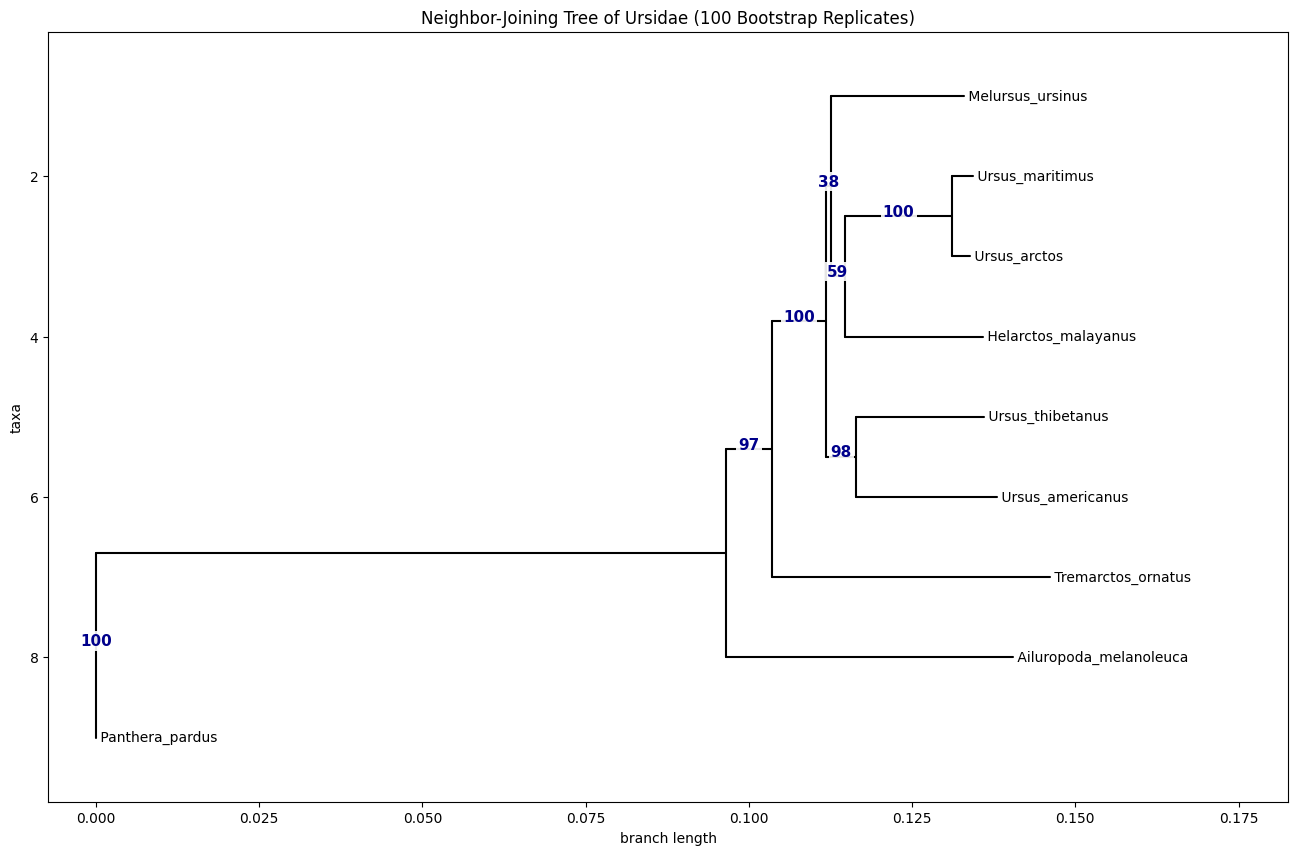

Tree saved as NJ_Ursidae_bootstrap.png


In [ ]:
import matplotlib.pyplot as plt
from Bio import Phylo

for clade in nj_tree.get_nonterminals():
    clade.name = None

root_children = nj_tree.root.clades

hidden_support = {
    clade: clade.confidence
    for clade in root_children
}

for clade in root_children:
    clade.confidence = None


fig, ax = plt.subplots(figsize=(16, 10))

Phylo.draw(
    nj_tree,
    axes=ax,
    do_show=False,
    show_confidence=True,
    label_func=lambda clade: clade.name if clade.is_terminal() else None
)


for text in ax.texts:
    label = text.get_text().strip()

    if label.replace(".", "", 1).isdigit():
        text.set_fontsize(11)
        text.set_color("darkblue")
        text.set_fontweight("bold")
        text.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.9,
            pad=1.5
        ))

ax.set_title(
    "Neighbor-Joining Tree of Ursidae (100 Bootstrap Replicates)"
)


plt.savefig(
    "NJ_Ursidae_bootstrap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


for clade, confidence in hidden_support.items():
    clade.confidence = confidence

plt.close(fig)

print("Tree saved as NJ_Ursidae_bootstrap.png")

### Результат шестого этапа

На дереве *Ailuropoda melanoleuca* отделяется раньше остальных медведей, затем *Tremarctos ornatus*.

Близкие группы *Ursus arctos* + *Ursus maritimus* и *Ursus americanus* + *Ursus thibetanus* имеют высокую бутстреп-поддержку (100% и 98%).

Некоторые внутренние узлы имеют низкую поддержку (38% и 59%), поэтому их положение нельзя считать надёжно установленным.

### 7. Филогенетическая реконструкция по методу максимального правдоподобия

Для построения филогенетического дерева методом максимального правдоподобия (ML) использовали программу IQ-TREE.

В терминале WSL выполнили команду:

```bash
iqtree2 -s combined.nex -B 1000 -alrt 1000 -pre combined
```


* Результаты IQ-TREE *

Анализ выполнен для 9 видов и 2414 нуклеотидных позиций. Программа выбрала модель `TIM2+F+I+G4`.

Лучшее значение логарифма правдоподобия составило **−7042.470**. Для оценки поддержки узлов использовали 1000 повторений Ultrafast Bootstrap и 1000 повторений SH-aLRT.

Лучшее ML-дерево сохранено в файле `combined.treefile`.

### Загрузка ML-дерева

**Результат:** дерево содержит 9 видов и первоначально не укоренено.

In [39]:
from Bio import Phylo

ml_tree = Phylo.read("combined.treefile", "newick")

print("ML tree loaded successfully!")
print("Taxa:", [tip.name for tip in ml_tree.get_terminals()])
print("Rooted:", ml_tree.rooted)

ML tree loaded successfully!
Taxa: ['Ailuropoda_melanoleuca', 'Helarctos_malayanus', 'Ursus_americanus', 'Ursus_thibetanus', 'Ursus_arctos', 'Ursus_maritimus', 'Melursus_ursinus', 'Panthera_pardus', 'Tremarctos_ornatus']
Rooted: False


### Укоренение ML-дерева

In [ ]:

ml_tree.root_with_outgroup("Panthera_pardus")

print("Rooted:", ml_tree.rooted)
print("Outgroup:", "Panthera_pardus")


Phylo.draw_ascii(ml_tree)

Rooted: True
Outgroup: Panthera_pardus
                                               _______ Ailuropoda_melanoleuca
                                              |
                                              |_____ Tremarctos_ornatus
                                              |
                                              |  _ Helarctos_malayanus
                                              |,|
  ____________________________________________||| _ Ursus_americanus
 |                                            ||||
 |                                            || | Ursus_thibetanus
 |                                            ||
 |                                            || , Ursus_arctos
_|                                            ||_|
 |                                             | | Ursus_maritimus
 |                                             |
 |                                             |_ Melursus_ursinus
 |
 | Panthera_pardus



### Проверка поддержки узлов

In [42]:
for clade in ml_tree.get_nonterminals():
    print("Node name:", repr(clade.name),
          "| Confidence:", clade.confidence)

Node name: None | Confidence: None
Node name: '5.5/54' | Confidence: None
Node name: None | Confidence: None
Node name: '91.2/65' | Confidence: None
Node name: '77.1/37' | Confidence: None
Node name: '59.3/35' | Confidence: None
Node name: '97.8/80' | Confidence: None
Node name: '100/98' | Confidence: None


** Визуализация и сохранение ML-дерева **

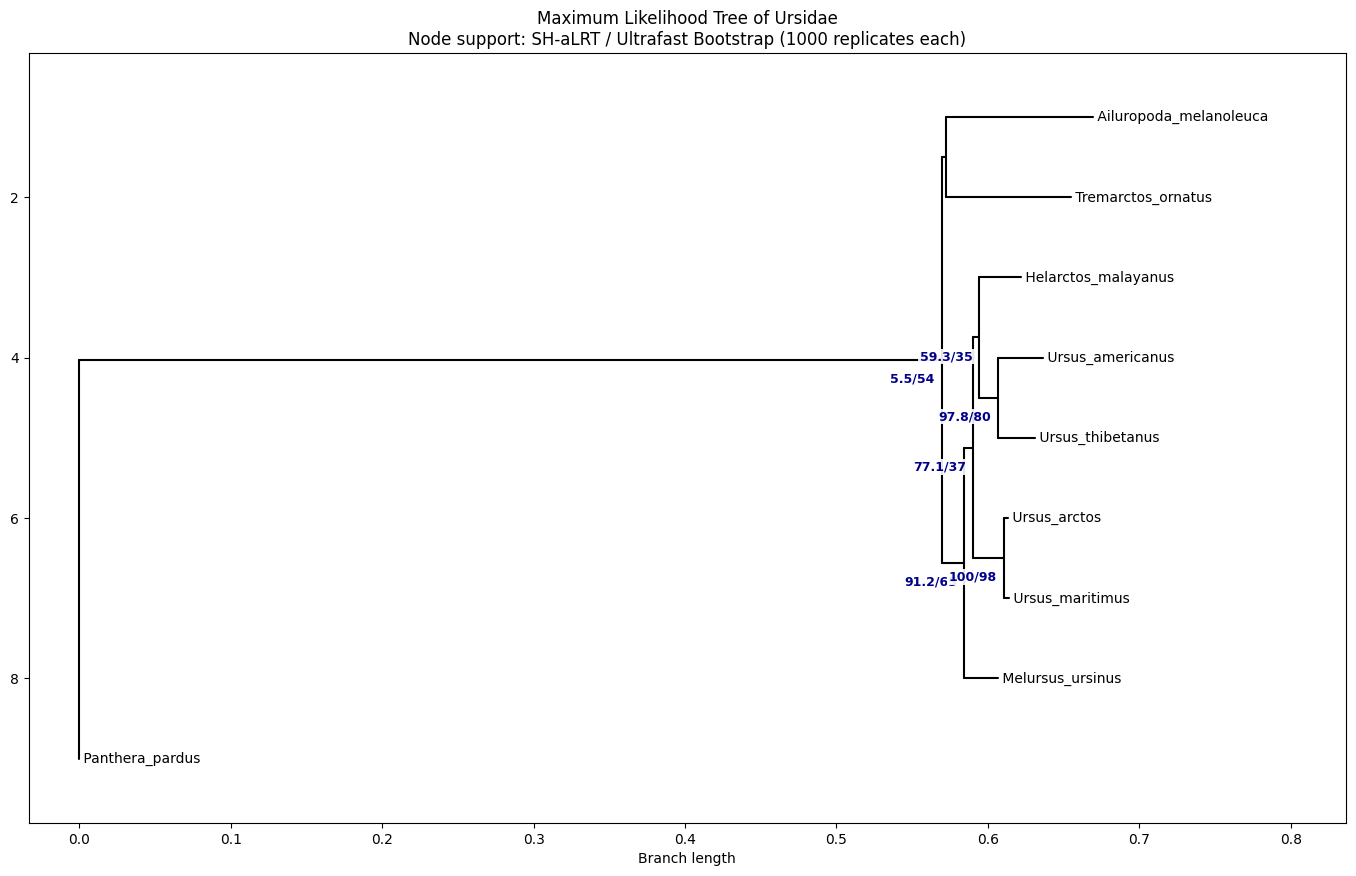

Tree saved as ML_Ursidae_bootstrap_SHaLRT.png


In [ ]:
import matplotlib.pyplot as plt
from Bio import Phylo

fig, ax = plt.subplots(figsize=(17, 10))

Phylo.draw(
    ml_tree,
    axes=ax,
    do_show=False,
    show_confidence=False,
    label_func=lambda clade: (
        clade.name if clade.is_terminal()
        else None
    )
)

x_positions = ml_tree.depths()
y_positions = {}

for i, tip in enumerate(ml_tree.get_terminals(), start=1):
    y_positions[tip] = i

def get_y_position(clade):
    if clade in y_positions:
        return y_positions[clade]

    child_y = [get_y_position(child) for child in clade.clades]
    y_positions[clade] = (child_y[0] + child_y[-1]) / 2
    return y_positions[clade]

get_y_position(ml_tree.root)

for clade in ml_tree.get_nonterminals():
    if clade.name and "/" in clade.name:
        ax.annotate(
            clade.name,
            xy=(x_positions[clade], y_positions[clade]),
            xytext=(-5, -9),
            textcoords="offset points",
            ha="right",
            va="top",
            fontsize=9,
            color="darkblue",
            fontweight="bold",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.9,
                pad=1
            )
        )

ax.set_title(
    "Maximum Likelihood Tree of Ursidae\n"
    "Node support: SH-aLRT / Ultrafast Bootstrap (1000 replicates each)"
)
ax.set_xlabel("Branch length")
ax.set_ylabel("")

plt.savefig(
    "ML_Ursidae_bootstrap_SHaLRT.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Tree saved as ML_Ursidae_bootstrap_SHaLRT.png")

### Соответствует ли дерево вашим ожиданиям?

В целом дерево соответствует ожиданиям. *Ursus arctos* и *Ursus maritimus* образуют близкую группу с высокой поддержкой (SH-aLRT/UFBoot = 100/98). *Ursus americanus* и *Ursus thibetanus* также образуют группу с поддержкой 97.8/80.

*Panthera pardus* используется как внешняя группа. Однако некоторые внутренние узлы имеют низкую поддержку (59.3/35 и 77.1/37), поэтому их положение остаётся неопределённым.

Основные группы в целом совпадают с деревом Neighbor-Joining, но есть различия во внутренней топологии.

## 8. Влияние разделения (partitioning)

Для генов CYTB и IRBP используем отдельные модели эволюции. Создали файл `partitions.nex`:

```nexus
#nexus
begin sets;
    charset CYTB = 1-1140;
    charset IRBP = 1141-2414;
end;
```

Запустили IQ-TREE в терминале WSL:

```bash
iqtree2 -s combined.nex -B 1000 -alrt 1000 -pre combined_partitioned -p partitions.nex
```

**Результат:** выбраны модели `HKY+F+R2` для CYTB и `HKY+F+G4` для IRBP. Log-likelihood = **−6739.625**. Дерево сохранено в `combined_partitioned.treefile`.

In [ ]:
# Загрузка и укоренение дерева
from Bio import Phylo

partitioned_ml_tree = Phylo.read(
    "combined_partitioned.treefile",
    "newick"
)

partitioned_ml_tree.root_with_outgroup("Panthera_pardus")

print("Partitioned ML tree loaded successfully!")
print("Rooted:", partitioned_ml_tree.rooted)
print("Number of taxa:", len(partitioned_ml_tree.get_terminals()))

Phylo.draw_ascii(partitioned_ml_tree)

Partitioned ML tree loaded successfully!
Rooted: True
Number of taxa: 9
                                                ____ Ailuropoda_melanoleuca
                                               |
                                               |  _ Helarctos_malayanus
                                               | |
  _____________________________________________| |, Melursus_ursinus
 |                                             |,||
 |                                             ||||, Ursus_americanus
 |                                             |||||
 |                                             ||||| Ursus_thibetanus
 |                                             || |
_|                                              | |, Ursus_arctos
 |                                              | ||
 |                                              |  | Ursus_maritimus
 |                                              |
 |                                              |_____ Tremarctos_ornatus
 |

### Проверка поддержки узлов

In [ ]:
for clade in partitioned_ml_tree.get_nonterminals():
    print(
        "Node name:", repr(clade.name),
        "| Confidence:", clade.confidence
    )

Node name: None | Confidence: None
Node name: None | Confidence: None
Node name: '77.2/56' | Confidence: None
Node name: '94.5/69' | Confidence: None
Node name: '83/37' | Confidence: None
Node name: '45.8/27' | Confidence: None
Node name: '99/80' | Confidence: None
Node name: '99.9/92' | Confidence: None


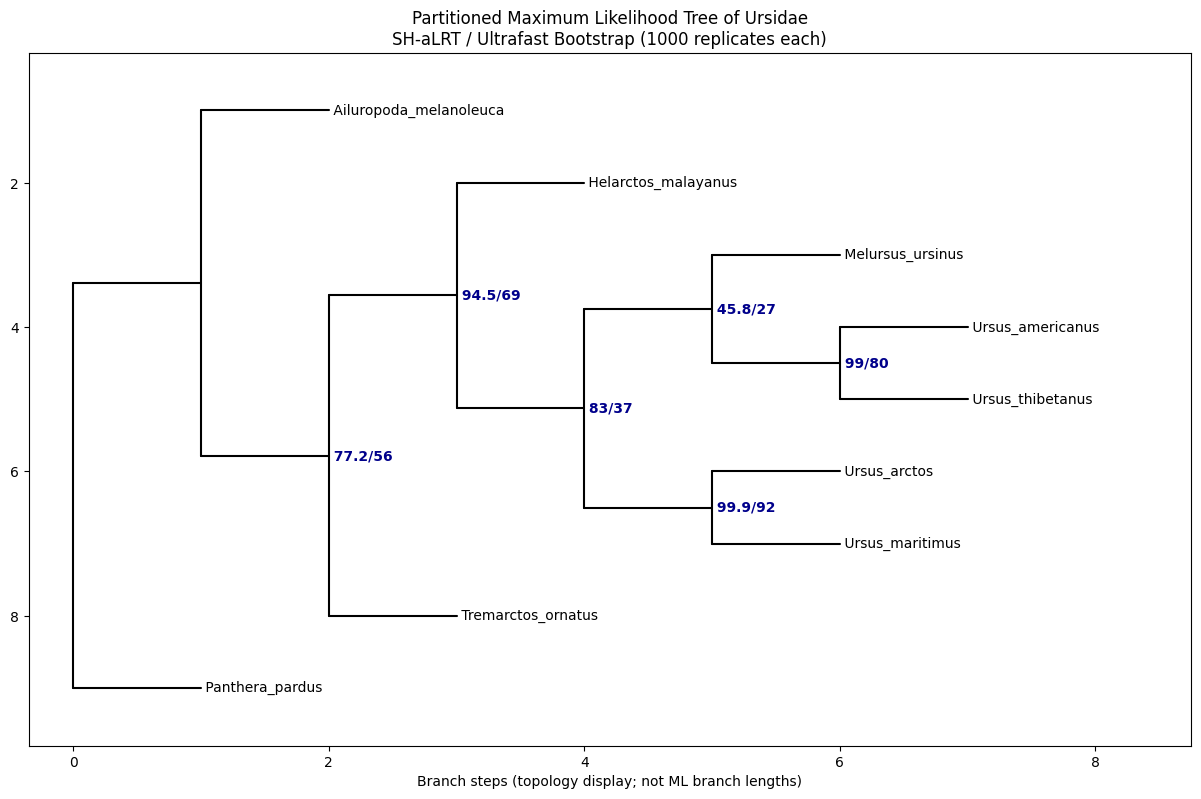

Tree saved as ML_Ursidae_partitioned.png


In [ ]:
# Визуализация и сохранение дерева
import copy
import matplotlib.pyplot as plt
from Bio import Phylo


display_tree = copy.deepcopy(partitioned_ml_tree)


for clade in display_tree.find_clades():
    if clade != display_tree.root:
        clade.branch_length = 1.0

fig, ax = plt.subplots(figsize=(15, 9))


Phylo.draw(
    display_tree,
    axes=ax,
    do_show=False,
    show_confidence=False,
    label_func=lambda clade: (
        clade.name if clade.is_terminal()
        else clade.name if clade.name and "/" in clade.name
        else None
    )
)


for label in ax.texts:
    if "/" in label.get_text():
        label.set_color("darkblue")
        label.set_fontsize(10)
        label.set_fontweight("bold")

ax.set_title(
    "Partitioned Maximum Likelihood Tree of Ursidae\n"
    "SH-aLRT / Ultrafast Bootstrap (1000 replicates each)"
)
ax.set_xlabel("Branch steps (topology display; not ML branch lengths)")
ax.set_ylabel("")

plt.savefig(
    "ML_Ursidae_partitioned.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Tree saved as ML_Ursidae_partitioned.png")

### Результат восьмого этапа

**Увидели ли вы какую-нибудь разницу?**

Да, разделение данных повлияло на топологию некоторых внутренних ветвей и значения статистической поддержки узлов (SH-aLRT/UFBoot). При этом основные группы сохранились:

- *Ursus arctos* + *Ursus maritimus*: 100/98 без разделения и 99.9/92 с разделением.
- *Ursus americanus* + *Ursus thibetanus*: 97.8/80 без разделения и 99/80 с разделением.

Однако некоторые внутренние узлы по-прежнему имеют низкую поддержку (например, 45.8/27 и 83/37), поэтому их положение остаётся неопределённым.

**Какое дерево более надёжно и почему?**

Дерево с разделением данных является более обоснованным с точки зрения моделирования, поскольку учитывает различия в эволюции ядерного гена IRBP и митохондриального гена CYTB. Однако разделение не привело к повышению поддержки всех узлов. Поэтому нельзя однозначно утверждать, что вся топология разделённого дерева более надёжна. Наиболее уверенными остаются группы с высокой статистической поддержкой.


## Дополнительные возможности метода Maximum Likelihood

Для более подробного анализа разделяем гены CYTB и IRBP по трём позициям кодонов. Получаем шесть исходных разделов.

Создали файл `partitions_codon.nex`:

```nexus
#nexus
begin sets;
    charset cytb_pos1 = 1-1140\3;
    charset cytb_pos2 = 2-1140\3;
    charset cytb_pos3 = 3-1140\3;
    charset irbp_pos1 = 1141-2414\3;
    charset irbp_pos2 = 1142-2414\3;
    charset irbp_pos3 = 1143-2414\3;
end;
```

### Запуск IQ-TREE с параметром --merge

В терминале WSL выполнили команду:

```bash
iqtree2 -s combined.nex -p partitions_codon.nex --merge -B 1000 -alrt 1000 -pre combined_codon_merge
```

**Результат:** из шести исходных разделов IQ-TREE выбрал пять по критерию BIC. Разделы `cytb_pos2` и `irbp_pos2` были объединены, остальные остались отдельными.

- BIC исходной схемы из шести разделов: **13070.706**.
- BIC выбранной схемы при поиске разделов: **13026.915**.
- BIC после окончательной оптимизации: **13021.4442**.
- Log-likelihood итогового дерева: **−6242.0002**.

Выбранная схема сохранена в `combined_codon_merge.best_scheme.nex`, а итоговое дерево — в `combined_codon_merge.treefile`.

In [ ]:
# Загрузка и укоренение ML-дерева
from Bio import Phylo

merged_ml_tree = Phylo.read(
    "combined_codon_merge.treefile",
    "newick"
)

merged_ml_tree.root_with_outgroup("Panthera_pardus")

print("Merged ML tree loaded successfully!")
print("Rooted:", merged_ml_tree.rooted)
print("Number of taxa:", len(merged_ml_tree.get_terminals()))

Phylo.draw_ascii(merged_ml_tree)

Merged ML tree loaded successfully!
Rooted: True
Number of taxa: 9
                                                ___ Ailuropoda_melanoleuca
                                               |
                                               |   _ Helarctos_malayanus
                                               |  |
                                               |  | _ Ursus_americanus
  _____________________________________________|  ||
 |                                             |  || Ursus_thibetanus
 |                                             |  |
 |                                             | _|_ Melursus_ursinus
 |                                             || |
_|                                             || , Ursus_arctos
 |                                             || |
 |                                              | | Ursus_maritimus
 |                                              |
 |                                              |_____ Tremarctos_ornatus
 |
 | P

In [ ]:
# Сравнение топологии и поддержки узлов
def get_clade_supports(tree):
    result = {}

    for clade in tree.get_nonterminals():
        taxa = frozenset(
            tip.name for tip in clade.get_terminals()
        )

        
        if len(taxa) <= 1 or len(taxa) == len(tree.get_terminals()):
            continue

        if clade.name and "/" in clade.name:
            result[taxa] = clade.name

    return result


old_supports = get_clade_supports(partitioned_ml_tree)
new_supports = get_clade_supports(merged_ml_tree)

all_clades = sorted(
    set(old_supports) | set(new_supports),
    key=lambda taxa: (len(taxa), sorted(taxa))
)

print("Clade comparison (SH-aLRT / UFBoot):\n")

for taxa in all_clades:
    print(", ".join(sorted(taxa)))
    print("  Previous:", old_supports.get(taxa, "Absent"))
    print("  Merged:  ", new_supports.get(taxa, "Absent"))
    print()

Clade comparison (SH-aLRT / UFBoot):

Ursus_americanus, Ursus_thibetanus
  Previous: 99/80
  Merged:   94.6/94

Ursus_arctos, Ursus_maritimus
  Previous: 99.9/92
  Merged:   94.2/92

Helarctos_malayanus, Ursus_americanus, Ursus_thibetanus
  Previous: Absent
  Merged:   81.5/42

Melursus_ursinus, Ursus_americanus, Ursus_thibetanus
  Previous: 45.8/27
  Merged:   Absent

Helarctos_malayanus, Melursus_ursinus, Ursus_americanus, Ursus_thibetanus
  Previous: Absent
  Merged:   71.8/33

Melursus_ursinus, Ursus_americanus, Ursus_arctos, Ursus_maritimus, Ursus_thibetanus
  Previous: 83/37
  Merged:   Absent

Helarctos_malayanus, Melursus_ursinus, Ursus_americanus, Ursus_arctos, Ursus_maritimus, Ursus_thibetanus
  Previous: 94.5/69
  Merged:   96.4/81

Helarctos_malayanus, Melursus_ursinus, Tremarctos_ornatus, Ursus_americanus, Ursus_arctos, Ursus_maritimus, Ursus_thibetanus
  Previous: 77.2/56
  Merged:   84.5/75



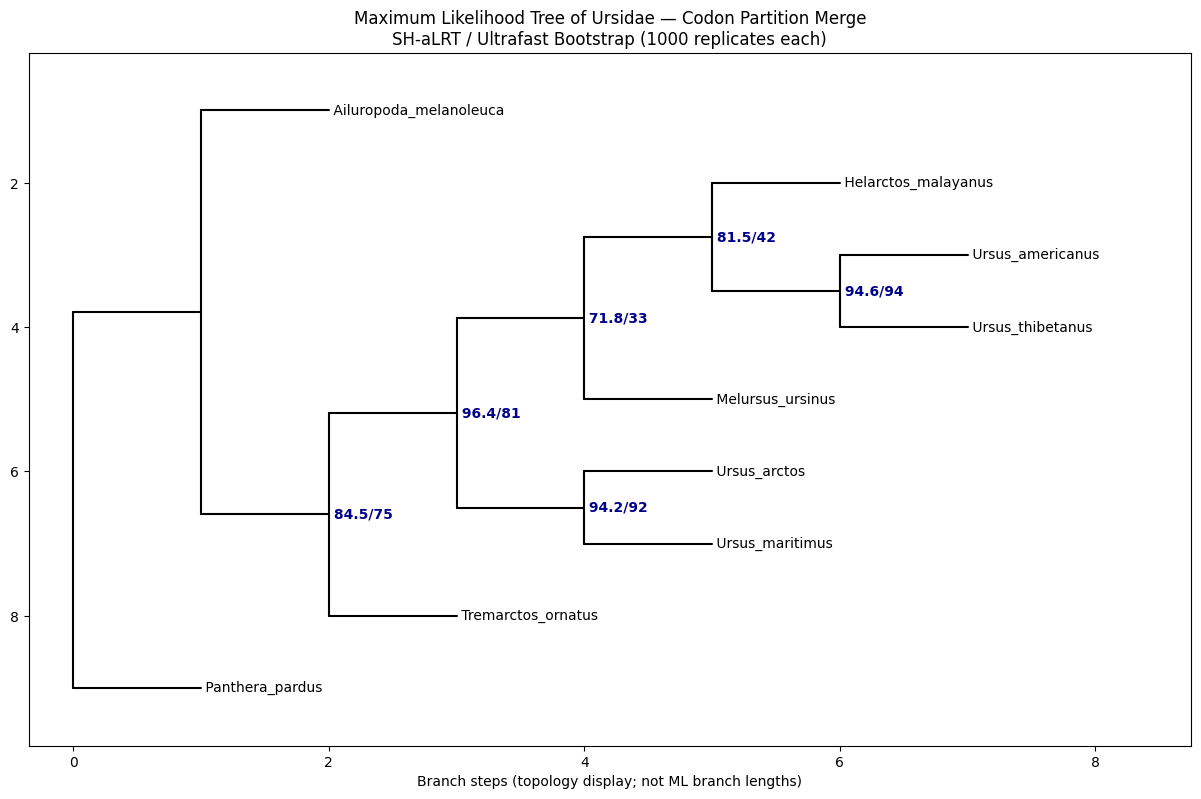

Tree saved as ML_Ursidae_codon_merge.png


In [ ]:
# Визуализация дерева после объединения разделов
import copy
import matplotlib.pyplot as plt
from Bio import Phylo

display_tree = copy.deepcopy(merged_ml_tree)


for clade in display_tree.find_clades():
    if clade != display_tree.root:
        clade.branch_length = 1.0

fig, ax = plt.subplots(figsize=(15, 9))

Phylo.draw(
    display_tree,
    axes=ax,
    do_show=False,
    show_confidence=False,
    label_func=lambda clade: (
        clade.name if clade.is_terminal()
        else clade.name if clade.name and "/" in clade.name
        else None
    )
)

for label in ax.texts:
    if "/" in label.get_text():
        label.set_color("darkblue")
        label.set_fontsize(10)
        label.set_fontweight("bold")

ax.set_title(
    "Maximum Likelihood Tree of Ursidae — Codon Partition Merge\n"
    "SH-aLRT / Ultrafast Bootstrap (1000 replicates each)"
)
ax.set_xlabel("Branch steps (topology display; not ML branch lengths)")
ax.set_ylabel("")

plt.savefig(
    "ML_Ursidae_codon_merge.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Tree saved as ML_Ursidae_codon_merge.png")

### Результат дополнительного анализа

**Какое разбиение было выбрано наилучшим?**

По критерию BIC (13026.915) IQ-TREE выбрал схему из **пяти разделов** вместо исходных шести. Вторые позиции кодонов генов CYTB и IRBP были объединены в один раздел, а остальные позиции анализировались отдельно. Таким образом, выбранная схема учитывает различия между позициями кодонов и допускает объединение разделов со сходными эволюционными характеристиками.

**Повлияло ли это на топологию и поддержку дерева?**

Да, оптимизация разделов привела к изменениям некоторых внутренних ветвей и значений их поддержки (SH-aLRT/UFBoot).

В частности, в новом дереве появилась группа *Helarctos malayanus* + (*Ursus americanus*, *Ursus thibetanus*) с поддержкой 81.5/42, отсутствовавшая в предыдущем дереве.

При этом две устойчивые группы сохранились:

- *Ursus americanus* + *Ursus thibetanus*: поддержка изменилась с 99/80 до 94.6/94.
- *Ursus arctos* + *Ursus maritimus*: поддержка изменилась с 99.9/92 до 94.2/92.

Несмотря на изменения, ряд внутренних узлов имеет недостаточную поддержку (например, 71.8/33 и 81.5/42), поэтому соответствующие эволюционные отношения нельзя считать надёжно установленными.

**Вывод:** схема из пяти разделов оказалась предпочтительной среди рассмотренных вариантов по критерию BIC. Она повлияла на часть топологии и статистическую поддержку ветвей, однако основные близкородственные пары сохранились. При этом оптимизация модели не устранила неопределённость некоторых внутренних узлов.